# Trajectory Visualization

This notebook reconstructs the 3D flight paths of pitches using the constant acceleration model.
It uses the robust `StatcastDataHandler` to load data from local Feather files.

In [1]:
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go

# --- CRITICAL FIX: Force autoreload to pick up src/physics.py changes ---
%load_ext autoreload
%autoreload 2

sys.path.append(os.path.abspath('../'))

from src.data_handler import StatcastDataHandler
from src.physics import calculate_trajectory

handler = StatcastDataHandler()

# Fetch a sample of pitches (from 2025 specifically, or whatever is available)
print("Loading data...")
df = handler.fetch_statcast(start_year=2025, end_year=2025)

# If 2025 is empty (fetch failed), try 2024 or earlier if user has files
if df.empty:
    print("2025 data empty, trying broader search (2020-2025)...")
    df = handler.fetch_statcast(start_year=2020, end_year=2025)

print(f"Loaded {len(df)} pitches")

Loading data...
Loading data from 2025 to 2025...
Loaded 726773 pitches


In [2]:
# Filter for valid physics data
if not df.empty:
    # Ensure necessary columns are present and not null
    valid_df = df.dropna(subset=['vx0', 'vy0', 'vz0', 'ax', 'ay', 'az', 'release_pos_x', 'plate_x', 'plate_z', 'pitch_type']).copy()
    print(f"Valid pitches for physics: {len(valid_df)}")

    if not valid_df.empty:
        # --- MODIFICATION: Filter for a single pitcher to show clustering ---
        # Find the pitcher with the most pitches in the dataset
        top_pitcher = valid_df['pitcher'].mode().iloc[0]
        pitcher_name = valid_df[valid_df['pitcher'] == top_pitcher]['player_name'].iloc[0] if 'player_name' in valid_df.columns else f'Pitcher {top_pitcher}'
        
        print(f"Filtering for Single Pitcher: {pitcher_name} (ID: {top_pitcher})")
        pitcher_df = valid_df[valid_df['pitcher'] == top_pitcher]
        
        # Limit to 100 sample pitches from this pitcher
        sample_df = pitcher_df.sample(min(100, len(pitcher_df)))
        
        # --- MODIFICATION: Define Pitch Type Colors ---
        # Custom colors provided by user
        color_map = {
            'FF': '#D22D49',
            'FT': '#DE6A04',
            'SI': '#FE9D00',
            'FC': '#933F2C',
            'CH': '#1DBE3A',
            'FS': '#3BACAC',
            'SC': '#60DB33',
            'FO': '#55CCAB',
            'ST': '#DDB33A',
            'SL': '#EEE716',
            'GY': '#FFFF99',
            'SV': '#93AFD4',
            'CU': '#00D1ED',
            'KC': '#6236CD',
            'KN': '#3C44CD',
            'CS': '#0068FF'
        }
        # Fallback color generator for unknown types
        def get_color(ptype):
            return color_map.get(ptype, 'gray')

        fig = go.Figure()

        # Handle Legend grouping
        added_to_legend = set()

        for idx, row in sample_df.iterrows():
            # Only process if we can calc trajectory
            traj = calculate_trajectory(row, time_step=0.01)
            if traj is not None:
                ptype = row['pitch_type']
                color = get_color(ptype)
                
                # Handle Legend: Show only once per pitch type
                show_legend = False
                if ptype not in added_to_legend:
                    show_legend = True
                    added_to_legend.add(ptype)
                
                fig.add_trace(go.Scatter3d(
                    x=traj['x'], y=traj['y'], z=traj['z'],
                    mode='lines',
                    name=ptype,
                    line=dict(width=2, color=color), 
                    opacity=0.6,
                    legendgroup=ptype, 
                    showlegend=show_legend
                ))

        # Add plate (approx)
        plate_x = [-0.83, 0.83, 0.83, -0.83, -0.83]
        plate_y = [1.417, 1.417, 0, 0, 1.417]
        plate_z = [0, 0, 0, 0, 0]
        fig.add_trace(go.Scatter3d(x=plate_x, y=plate_y, z=plate_z, mode='lines', name='Home Plate', line=dict(color='black', width=4)))

        # Add Strike Zone (generic)
        sz_top = 3.5
        sz_bot = 1.5
        fig.add_trace(go.Scatter3d(
            x=[-0.83, 0.83, 0.83, -0.83, -0.83], 
            y=[1.417, 1.417, 1.417, 1.417, 1.417], 
            z=[sz_bot, sz_bot, sz_top, sz_top, sz_bot],
            mode='lines',
            name='Strike Zone',
            line=dict(color='red', dash='dash', width=4)
        ))

        fig.update_layout(
            scene=dict(
                xaxis_title='X (ft)',
                yaxis_title='Y (ft)',
                zaxis_title='Z (ft)',
                
                # Force Long Y Axis Box
                aspectmode='manual',
                aspectratio=dict(x=1, y=10, z=1),
                
                xaxis=dict(range=[-3, 3]),
                yaxis=dict(range=[0, 60.5]), 
                zaxis=dict(range=[0, 7]),
                
                camera=dict(
                    eye=dict(x=0, y=2, z=0.5) 
                )
            ),
            title=f"Pitch Trajectories: {pitcher_name}",
            margin=dict(l=0, r=0, b=0, t=40)
        )

        fig.show()
else:
    print("No data available to plot.")

Valid pitches for physics: 724002
Filtering for Single Pitcher: Snell, Blake (ID: 592332)



--- Accuracy Validation (Calc vs. Actual) ---
             err_x        err_z
count  1000.000000  1000.000000
mean      0.000160     0.000347
std       0.004001     0.004178
min      -0.009010    -0.012218
25%      -0.002706    -0.002825
50%       0.000054     0.000368
75%       0.003046     0.003442
max       0.015209     0.009856


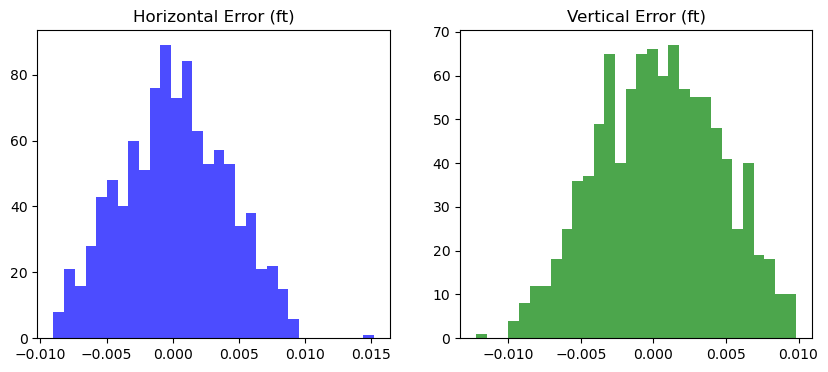

In [3]:
# Verify accuracy: Compare calculated final X/Z to actual plate_x/plate_z
if not df.empty and not valid_df.empty:
    errors = []
    # Use a larger sample for stats
    stats_df = valid_df.sample(min(1000, len(valid_df)))
    
    for idx, row in stats_df.iterrows():
        traj = calculate_trajectory(row, time_step=0.001)
        if traj is not None:
            final_pt = traj.iloc[-1]
            
            err_x = final_pt['x'] - row['plate_x']
            err_z = final_pt['z'] - row['plate_z']
            errors.append({'pitch_type': row['pitch_type'], 'err_x': err_x, 'err_z': err_z})

    err_df = pd.DataFrame(errors)
    print("\n--- Accuracy Validation (Calc vs. Actual) ---")
    print(err_df[['err_x', 'err_z']].describe())
    
    # Plot hist of errors
    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.hist(err_df['err_x'], bins=30, color='blue', alpha=0.7)
    plt.title('Horizontal Error (ft)')
    plt.subplot(1, 2, 2)
    plt.hist(err_df['err_z'], bins=30, color='green', alpha=0.7)
    plt.title('Vertical Error (ft)')
    plt.show()